# TerminalBench 2.1 reported vs calculated token audit

This notebook traverses **only the curated TerminalBench 2.1 corpus**. For every trajectory it records:

- token usage reported by the downloaded metadata;
- a model-specific token count where a supported local tokenizer is available;
- an explicitly labelled common-tokenizer fallback otherwise; and
- the difference between reported usage and counts reconstructed from visible trajectory content.

The reported values are treated as **harness/provider-reported usage**, not unquestionable ground truth. The calculated values are an audit of observable content, not a reconstruction of hidden system prompts or exact billing payloads.

## Interpretation guardrails

1. Tokenizers differ by model. When `tiktoken` is available, the notebook first asks it for a model-specific encoding and otherwise uses `o200k_base` as a common counter. If `tiktoken` is unavailable, a dependency-free UTF-8 estimate is used and explicitly labelled as approximate in `counter_method` and `counter_quality`.
2. Provider token-count APIs are not called for the full corpus. They require credentials, network requests and the exact original request payload, while our normalized data does not retain every system prompt and tool schema.
3. `thought` and `action` are treated as visible model output. `observation` is environment/tool output that becomes input on a later model turn.
4. A transcript counted once is only a lower bound. The cumulative estimate counts visible history again before each inferred model turn.
5. Consecutive normalized steps sharing one timestamp are grouped into one inferred model turn because one raw ATIF response may contain multiple tool calls. When timestamps are absent, one normalized step is treated as one turn.
6. A remaining gap can represent missing harness context, tool schemas, retries, summaries, caching rules, hidden reasoning, truncation, serialization overhead, or an imperfect tokenizer—not necessarily hidden reasoning alone.

In [34]:
# Reuse tiktoken from the notebook environment or its base Python installation.
import site
import sys
from pathlib import Path

try:
    import tiktoken
except ModuleNotFoundError:
    # A virtual environment may hide packages installed in its compatible base Python.
    base_site_packages = Path(sys.base_prefix) / "Lib" / "site-packages"
    if base_site_packages.exists():
        site.addsitedir(str(base_site_packages))
    try:
        import tiktoken
    except ModuleNotFoundError:
        tiktoken = None

print(f"Notebook Python: {sys.executable}")
if tiktoken is None:
    print("tiktoken is unavailable; the notebook will use the labelled common approximation.")
else:
    print(f"tiktoken {tiktoken.__version__} is available.")

Notebook Python: d:\Studies\UZH-M.Sc\THESIS\design-decisions-by-LLMs\.venv\Scripts\python.exe
tiktoken 0.14.0 is available.


In [35]:
from __future__ import annotations

import json
import math
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:
    import tiktoken
except ModuleNotFoundError:
    tiktoken = None
from IPython.display import Markdown, display
from tqdm.auto import tqdm

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 140)

In [36]:
def find_project_root() -> Path:
    candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / "design-decisions-by-LLMs"]
    for candidate in candidates:
        target = candidate / "data" / "curated" / "terminal_bench_2_1" / "trajectories.jsonl"
        if target.exists():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate design-decisions-by-LLMs/data/curated/terminal_bench_2_1/trajectories.jsonl")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "curated" / "terminal_bench_2_1"
TRAJECTORY_PATH = DATA_DIR / "trajectories.jsonl"
SUMMARY_PATH = DATA_DIR / "summary.json"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_CSV = OUTPUT_DIR / "terminalbench21_token_audit.csv"
MODEL_SUMMARY_CSV = OUTPUT_DIR / "terminalbench21_token_audit_by_model.csv"
AGENT_SUMMARY_CSV = OUTPUT_DIR / "terminalbench21_token_audit_by_agent.csv"

COMMON_ENCODING = "o200k_base"
REUSE_EXISTING_AUDIT = True
MAX_TRAJECTORIES = None  # Keep None for the complete TerminalBench 2.1 corpus.
AUDIT_VERSION = "tb21-token-audit-v1"

with SUMMARY_PATH.open(encoding="utf-8") as handle:
    corpus_summary = json.load(handle)

assert corpus_summary["benchmark"] == "terminal_bench_2_1"
EXPECTED_ROWS = int(corpus_summary["counts"]["output_rows"])
print(f"Project root: {PROJECT_ROOT}")
print(f"Input: {TRAJECTORY_PATH}")
print(f"Expected TerminalBench 2.1 trajectories: {EXPECTED_ROWS:,}")

Project root: D:\Studies\UZH-M.Sc\THESIS\design-decisions-by-LLMs
Input: D:\Studies\UZH-M.Sc\THESIS\design-decisions-by-LLMs\data\curated\terminal_bench_2_1\trajectories.jsonl
Expected TerminalBench 2.1 trajectories: 8,640


## Token-counter policy

`tiktoken.encoding_for_model()` is used when it recognises an OpenAI model name. Modern GPT-family names that are not yet present in the installed registry use the GPT-family `o200k_base` encoding. Every other model uses the same `o200k_base` fallback so comparisons remain reproducible.

This does **not** claim that `o200k_base` is the native Claude, Gemini, GLM, Grok, Muse or synthetic tokenizer. Those rows are marked `common-fallback`. The notebook reports results separately by counter quality.

In [37]:
class CommonApproxEncoding:
    """Dependency-free fallback: approximately one token per four UTF-8 bytes."""

    name = "utf8-four-byte-estimate"

    def encode(self, text: str, disallowed_special=()):
        byte_count = len(str(text).encode("utf-8"))
        estimated_count = math.ceil(byte_count / 4) if byte_count else 0
        return range(estimated_count)


COMMON_COUNTER = (
    tiktoken.get_encoding(COMMON_ENCODING)
    if tiktoken is not None
    else CommonApproxEncoding()
)

def canonical_model_name(model: object) -> str:
    value = str(model or "unknown").strip().lower()
    return value.split("/")[-1]

@lru_cache(maxsize=None)
def counter_for_model(model: str):
    canonical = canonical_model_name(model)

    # Ask the installed tiktoken registry first. This is the strongest local match.
    if tiktoken is not None:
        try:
            encoding = tiktoken.encoding_for_model(canonical)
            return encoding, f"tiktoken:{encoding.name}:registry", "model-specific"
        except KeyError:
            pass

    # GPT-5.x model aliases in this corpus use the modern OpenAI tokenizer family.
    if tiktoken is not None and canonical.startswith(("gpt-5", "gpt-4o", "o1", "o3", "o4")):
        return COMMON_COUNTER, f"tiktoken:{COMMON_ENCODING}:openai-family", "family-specific"

    if tiktoken is not None:
        return COMMON_COUNTER, f"tiktoken:{COMMON_ENCODING}:common-fallback", "common-fallback"

    return COMMON_COUNTER, "utf8:four-byte-estimate", "approximate-fallback"

def count_text(value: object, encoding) -> int:
    if value is None:
        return 0
    text = str(value)
    if not text:
        return 0
    return len(encoding.encode(text, disallowed_special=()))

# Show the policy for every model before the expensive full traversal.
model_policy_preview = []
with TRAJECTORY_PATH.open(encoding="utf-8") as handle:
    seen = set()
    for line in handle:
        row = json.loads(line)
        model = str(row.get("model") or "unknown")
        if model in seen:
            continue
        seen.add(model)
        _, method, quality = counter_for_model(model)
        model_policy_preview.append({"model": model, "counter_method": method, "counter_quality": quality})

pd.DataFrame(model_policy_preview).sort_values(["counter_quality", "model"]).reset_index(drop=True)

,model,counter_method,counter_quality
0,<synthetic>,tiktoken:o200k_base:common-fallback,common-fallback
1,anthropic/claude-fable-5,tiktoken:o200k_base:common-fallback,common-fallback
2,anthropic/claude-opus-4-7,tiktoken:o200k_base:common-fallback,common-fallback
3,claude-fable-5,tiktoken:o200k_base:common-fallback,common-fallback
4,claude-opus-4-7,tiktoken:o200k_base:common-fallback,common-fallback
5,claude-opus-4-8,tiktoken:o200k_base:common-fallback,common-fallback
6,claude-sonnet-5,tiktoken:o200k_base:common-fallback,common-fallback
7,cursor/grok-4.5,tiktoken:o200k_base:common-fallback,common-fallback
8,gemini-3.1-pro-preview,tiktoken:o200k_base:common-fallback,common-fallback
9,gemini-3.1-pro-preview-customtools,tiktoken:o200k_base:common-fallback,common-fallback


In [38]:
def numeric_or_nan(value: object) -> float:
    try:
        return float(value) if value is not None else math.nan
    except (TypeError, ValueError):
        return math.nan

def inferred_turn_groups(steps: list[dict]) -> list[list[int]]:
    groups: list[list[int]] = []
    previous_key = None
    for position, step in enumerate(steps):
        timestamp = step.get("timestamp")
        key = ("timestamp", timestamp) if timestamp else ("step", position)
        if not groups or key != previous_key:
            groups.append([])
        groups[-1].append(position)
        previous_key = key
    return groups

def audit_trajectory(record: dict) -> dict:
    if record.get("source") != "tbench21":
        raise ValueError(f"Unexpected non-TerminalBench-2.1 source: {record.get('source')}")

    model = str(record.get("model") or "unknown")
    encoding, counter_method, counter_quality = counter_for_model(model)
    steps = record.get("steps") or []
    meta = record.get("meta") or {}
    downloaded = meta.get("downloaded_metadata") or {}

    task_tokens = count_text(meta.get("task_prompt"), encoding)
    thought_counts = [count_text(step.get("thought"), encoding) for step in steps]
    action_counts = [count_text(step.get("action"), encoding) for step in steps]
    observation_counts = [count_text(step.get("observation"), encoding) for step in steps]

    calculated_thought_tokens = sum(thought_counts)
    calculated_action_tokens = sum(action_counts)
    calculated_observation_tokens = sum(observation_counts)
    calculated_completion_tokens = calculated_thought_tokens + calculated_action_tokens
    calculated_prompt_once_tokens = task_tokens + calculated_observation_tokens
    calculated_visible_total_once_tokens = calculated_prompt_once_tokens + calculated_completion_tokens

    # Approximate repeated context: count all visible prior content before each inferred model turn.
    visible_history_tokens = task_tokens
    calculated_cumulative_prompt_tokens = 0
    groups = inferred_turn_groups(steps)
    for group in groups:
        calculated_cumulative_prompt_tokens += visible_history_tokens
        for position in group:
            visible_history_tokens += thought_counts[position]
            visible_history_tokens += action_counts[position]
            visible_history_tokens += observation_counts[position]

    calculated_cumulative_total_tokens = calculated_cumulative_prompt_tokens + calculated_completion_tokens

    reported_prompt = numeric_or_nan(downloaded.get("prompt_tokens"))
    reported_completion = numeric_or_nan(downloaded.get("completion_tokens"))
    reported_total = numeric_or_nan(downloaded.get("total_tokens"))
    reported_available = not any(math.isnan(v) for v in (reported_prompt, reported_completion, reported_total))

    return {
        "audit_version": AUDIT_VERSION,
        "id": record.get("id"),
        "trial_id": record.get("trial_id"),
        "task_id": record.get("task_id"),
        "task_name": downloaded.get("task_name"),
        "agent": record.get("agent"),
        "model": model,
        "resolved": record.get("resolved"),
        "resolved_available": bool(record.get("resolved_available")),
        "difficulty": downloaded.get("difficulty"),
        "normalized_step_count": len(steps),
        "inferred_model_turn_count": len(groups),
        "reported_step_count": numeric_or_nan(downloaded.get("step_count")),
        "tool_call_count": numeric_or_nan(downloaded.get("tool_call_count")),
        "command_count": numeric_or_nan(downloaded.get("command_count")),
        "duration_seconds": numeric_or_nan(downloaded.get("duration_seconds")),
        "counter_method": counter_method,
        "counter_quality": counter_quality,
        "reported_available": reported_available,
        "reported_prompt_tokens": reported_prompt,
        "reported_completion_tokens": reported_completion,
        "reported_total_tokens": reported_total,
        "reported_component_sum": reported_prompt + reported_completion if reported_available else math.nan,
        "calculated_task_tokens": task_tokens,
        "calculated_thought_tokens": calculated_thought_tokens,
        "calculated_action_tokens": calculated_action_tokens,
        "calculated_observation_tokens": calculated_observation_tokens,
        "calculated_prompt_once_tokens": calculated_prompt_once_tokens,
        "calculated_completion_tokens": calculated_completion_tokens,
        "calculated_visible_total_once_tokens": calculated_visible_total_once_tokens,
        "calculated_cumulative_prompt_tokens": calculated_cumulative_prompt_tokens,
        "calculated_cumulative_total_tokens": calculated_cumulative_total_tokens,
        "steps_with_thought": sum(bool(step.get("thought")) for step in steps),
        "steps_with_action": sum(bool(step.get("action")) for step in steps),
        "steps_with_observation": sum(bool(step.get("observation")) for step in steps),
        "trajectory_file": downloaded.get("rel_path"),
    }

def build_audit(path: Path, limit: int | None = None) -> pd.DataFrame:
    expected = min(EXPECTED_ROWS, limit) if limit is not None else EXPECTED_ROWS
    rows = []
    with path.open(encoding="utf-8") as handle:
        for index, line in enumerate(tqdm(handle, total=expected, desc="Counting TerminalBench 2.1")):
            if limit is not None and index >= limit:
                break
            rows.append(audit_trajectory(json.loads(line)))
    result = pd.DataFrame(rows)
    if limit is None:
        assert len(result) == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS:,} rows, found {len(result):,}"
    return result

In [39]:
can_reuse = False
if REUSE_EXISTING_AUDIT and AUDIT_CSV.exists() and MAX_TRAJECTORIES is None:
    cached = pd.read_csv(AUDIT_CSV, low_memory=False)
    can_reuse = (
        len(cached) == EXPECTED_ROWS
        and "audit_version" in cached.columns
        and cached["audit_version"].eq(AUDIT_VERSION).all()
    )

if can_reuse:
    audit_df = cached
    print(f"Loaded cached audit: {AUDIT_CSV}")
else:
    audit_df = build_audit(TRAJECTORY_PATH, MAX_TRAJECTORIES)
    if MAX_TRAJECTORIES is None:
        audit_df.to_csv(AUDIT_CSV, index=False)
        print(f"Saved row-level audit: {AUDIT_CSV}")

print(f"Audited trajectories: {len(audit_df):,}")
print(f"Reported token data available: {audit_df['reported_available'].sum():,}")
print(f"Reported token data unavailable: {(~audit_df['reported_available'].astype(bool)).sum():,}")
audit_df.head(3)

Loaded cached audit: D:\Studies\UZH-M.Sc\THESIS\design-decisions-by-LLMs\outputs\terminalbench21_token_audit.csv
Audited trajectories: 8,640
Reported token data available: 7,364
Reported token data unavailable: 1,276


,audit_version,id,trial_id,task_id,task_name,agent,model,resolved,resolved_available,difficulty,normalized_step_count,inferred_model_turn_count,reported_step_count,tool_call_count,command_count,duration_seconds,counter_method,counter_quality,reported_available,reported_prompt_tokens,reported_completion_tokens,reported_total_tokens,reported_component_sum,calculated_task_tokens,calculated_thought_tokens,calculated_action_tokens,calculated_observation_tokens,calculated_prompt_once_tokens,calculated_completion_tokens,calculated_visible_total_once_tokens,calculated_cumulative_prompt_tokens,calculated_cumulative_total_tokens,steps_with_thought,steps_with_action,steps_with_observation,trajectory_file,reported_component_gap,calculated_minus_reported_prompt,calculated_minus_reported_completion,calculated_minus_reported_total,reported_to_calculated_once_ratio,reported_to_calculated_cumulative_ratio,reported_to_calculated_prompt_ratio,reported_to_calculated_completion_ratio,cumulative_total_abs_pct_error,once_total_abs_pct_error
0,tb21-token-audit-v1,tbench21:00434eba-54e1-5d9c-9941-3eba33466b6d,00434eba-54e1-5d9c-9941-3eba33466b6d,terminal-bench/headless-terminal,headless-terminal,claude-code,claude-opus-4-8,True,True,medium,10,8,9.0,9.0,7.0,199.260956,tiktoken:o200k_base:common-fallback,common-fallback,True,57536.0,11495.0,69031.0,69031.0,151,578,1342,6184,6335,1920,8255,25058,26978,8,9,7,claude-code\claude-fable-5\headless-terminal_00434eba-54e1-5d9c-9941-3eba33466b6d.json,0.0,-32478.0,-9575.0,-42053.0,8.362326,2.558789,2.296113,5.986979,0.609190,0.880416
1,tb21-token-audit-v1,tbench21:0095ac4f-281a-55d6-ac0d-2789ea5293d8,0095ac4f-281a-55d6-ac0d-2789ea5293d8,terminal-bench/install-windows-3.11,install-windows-3.11,claude-code,claude-fable-5,True,True,hard,59,51,52.0,58.0,51.0,744.618630,tiktoken:o200k_base:common-fallback,common-fallback,True,1530520.0,30392.0,1560912.0,1560912.0,219,1004,5447,73395,73614,6451,80065,1768149,1774600,51,58,50,claude-code\claude-fable-5\install-windows-3.11_0095ac4f-281a-55d6-ac0d-2789ea5293d8.json,0.0,237629.0,-23941.0,213688.0,19.495560,0.879585,0.865606,4.711208,0.136899,0.948706
2,tb21-token-audit-v1,tbench21:0124c887-471f-53b1-aefe-c04a3c7b528b,0124c887-471f-53b1-aefe-c04a3c7b528b,terminal-bench/rstan-to-pystan,rstan-to-pystan,claude-code,claude-fable-5,True,True,medium,112,111,115.0,108.0,77.0,1067.334465,tiktoken:o200k_base:common-fallback,common-fallback,True,4550052.0,45323.0,4595375.0,4595375.0,433,2014,6530,34535,34968,8544,43512,2541164,2549708,81,108,107,claude-code\claude-fable-5\rstan-to-pystan_0124c887-471f-53b1-aefe-c04a3c7b528b.json,0.0,-2008888.0,-36779.0,-2045667.0,105.611670,1.802314,1.790539,5.304658,0.445158,0.990531


## Differences and ratios

The main calculated comparison uses `calculated_cumulative_total_tokens`. The one-pass value remains available as a lower-bound diagnostic. Positive `calculated_minus_reported_*` values mean the reconstructed value is larger. A ratio above 1 in `reported_to_calculated_*` means reported usage is larger.

In [40]:
audit_df["reported_component_gap"] = audit_df["reported_total_tokens"] - audit_df["reported_component_sum"]
audit_df["calculated_minus_reported_prompt"] = audit_df["calculated_cumulative_prompt_tokens"] - audit_df["reported_prompt_tokens"]
audit_df["calculated_minus_reported_completion"] = audit_df["calculated_completion_tokens"] - audit_df["reported_completion_tokens"]
audit_df["calculated_minus_reported_total"] = audit_df["calculated_cumulative_total_tokens"] - audit_df["reported_total_tokens"]
audit_df["reported_to_calculated_once_ratio"] = audit_df["reported_total_tokens"] / audit_df["calculated_visible_total_once_tokens"].replace(0, np.nan)
audit_df["reported_to_calculated_cumulative_ratio"] = audit_df["reported_total_tokens"] / audit_df["calculated_cumulative_total_tokens"].replace(0, np.nan)
audit_df["reported_to_calculated_prompt_ratio"] = audit_df["reported_prompt_tokens"] / audit_df["calculated_cumulative_prompt_tokens"].replace(0, np.nan)
audit_df["reported_to_calculated_completion_ratio"] = audit_df["reported_completion_tokens"] / audit_df["calculated_completion_tokens"].replace(0, np.nan)
audit_df["cumulative_total_abs_pct_error"] = (
    audit_df["calculated_minus_reported_total"].abs() / audit_df["reported_total_tokens"].replace(0, np.nan)
)
audit_df["once_total_abs_pct_error"] = (
    (audit_df["calculated_visible_total_once_tokens"] - audit_df["reported_total_tokens"]).abs()
    / audit_df["reported_total_tokens"].replace(0, np.nan)
)

if MAX_TRAJECTORIES is None:
    audit_df.to_csv(AUDIT_CSV, index=False)

reported = audit_df[audit_df["reported_available"].astype(bool)].copy()
print(f"Comparison rows: {len(reported):,}")
reported[["reported_total_tokens", "calculated_visible_total_once_tokens", "calculated_cumulative_total_tokens", "reported_to_calculated_cumulative_ratio"]].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])

Comparison rows: 7,364


,reported_total_tokens,calculated_visible_total_once_tokens,calculated_cumulative_total_tokens,reported_to_calculated_cumulative_ratio
count,7.364000e+03,7.364000e+03,7.364000e+03,7364.000000
mean,1.071900e+06,2.587861e+04,7.999428e+05,5.443157
std,2.743250e+06,6.417331e+04,4.483152e+06,32.663747
min,0.000000e+00,8.100000e+01,7.100000e+01,0.000000
25%,9.661475e+04,5.125750e+03,2.625025e+04,1.669364
50%,2.824410e+05,1.180850e+04,9.911800e+04,2.332211
75%,8.612698e+05,2.632625e+04,3.933235e+05,3.885721
90%,2.378943e+06,5.929860e+04,1.491334e+06,7.873215
99%,1.355997e+07,1.779999e+05,1.124450e+07,38.390378
max,5.582496e+07,2.676676e+06,2.661574e+08,1521.028169


In [41]:
coverage = (
    audit_df.groupby(["counter_quality", "counter_method"], dropna=False)
    .agg(
        trajectories=("id", "size"),
        reported_available=("reported_available", "sum"),
        models=("model", "nunique"),
        agents=("agent", "nunique"),
    )
    .reset_index()
)
coverage["reported_coverage_pct"] = 100 * coverage["reported_available"] / coverage["trajectories"]
coverage.sort_values("trajectories", ascending=False)

,counter_quality,counter_method,trajectories,reported_available,models,agents,reported_coverage_pct
0,common-fallback,tiktoken:o200k_base:common-fallback,5639,5594,14,5,99.201986
1,model-specific,tiktoken:o200k_base:registry,3001,1770,5,2,58.980340


In [42]:
component_gap = reported["reported_component_gap"].abs()
display(Markdown(
    f"**Reported-token sanity check:** {int((component_gap == 0).sum()):,} of {len(reported):,} rows satisfy "
    f"`reported_total = reported_prompt + reported_completion` exactly. "
    f"Maximum absolute component gap: {component_gap.max():,.0f} tokens."
))
reported.loc[component_gap.nlargest(10).index, ["id", "agent", "model", "reported_prompt_tokens", "reported_completion_tokens", "reported_total_tokens", "reported_component_gap"]]

**Reported-token sanity check:** 7,364 of 7,364 rows satisfy `reported_total = reported_prompt + reported_completion` exactly. Maximum absolute component gap: 0 tokens.

,id,agent,model,reported_prompt_tokens,reported_completion_tokens,reported_total_tokens,reported_component_gap
0,tbench21:00434eba-54e1-5d9c-9941-3eba33466b6d,claude-code,claude-opus-4-8,57536.0,11495.0,69031.0,0.0
1,tbench21:0095ac4f-281a-55d6-ac0d-2789ea5293d8,claude-code,claude-fable-5,1530520.0,30392.0,1560912.0,0.0
2,tbench21:0124c887-471f-53b1-aefe-c04a3c7b528b,claude-code,claude-fable-5,4550052.0,45323.0,4595375.0,0.0
3,tbench21:0182a355-29db-50af-bb4d-7f6f6a73aa73,claude-code,claude-fable-5,50497.0,3950.0,54447.0,0.0
4,tbench21:01958175-c1f9-58a0-b005-82a8630501ec,claude-code,claude-opus-4-8,96022.0,15273.0,111295.0,0.0
5,tbench21:019e33a2-dc96-5f1b-b8e0-d08986be1303,claude-code,claude-fable-5,70512.0,8547.0,79059.0,0.0
6,tbench21:01c7c4cd-a911-58be-a1b5-c77bdc543a21,claude-code,claude-fable-5,52112.0,2867.0,54979.0,0.0
7,tbench21:01e7a3fc-f6ec-5577-803b-0b7df7e3fece,claude-code,claude-fable-5,306346.0,6335.0,312681.0,0.0
8,tbench21:024ed67f-4366-5e29-8496-e05f28b0bcb5,claude-code,claude-fable-5,13192.0,1548.0,14740.0,0.0
9,tbench21:02e999eb-9c20-5916-af73-73f06d367429,claude-code,claude-fable-5,58121.0,7010.0,65131.0,0.0


In [43]:
global_summary = pd.DataFrame({
    "metric": [
        "reported prompt",
        "calculated cumulative visible prompt",
        "reported completion",
        "calculated visible completion",
        "reported total",
        "calculated visible total once",
        "calculated cumulative visible total",
    ],
    "mean_tokens": [
        reported["reported_prompt_tokens"].mean(),
        reported["calculated_cumulative_prompt_tokens"].mean(),
        reported["reported_completion_tokens"].mean(),
        reported["calculated_completion_tokens"].mean(),
        reported["reported_total_tokens"].mean(),
        reported["calculated_visible_total_once_tokens"].mean(),
        reported["calculated_cumulative_total_tokens"].mean(),
    ],
    "median_tokens": [
        reported["reported_prompt_tokens"].median(),
        reported["calculated_cumulative_prompt_tokens"].median(),
        reported["reported_completion_tokens"].median(),
        reported["calculated_completion_tokens"].median(),
        reported["reported_total_tokens"].median(),
        reported["calculated_visible_total_once_tokens"].median(),
        reported["calculated_cumulative_total_tokens"].median(),
    ],
})
global_summary.round({"mean_tokens": 1, "median_tokens": 1})

,metric,mean_tokens,median_tokens
0,reported prompt,1049310.7,265346.0
1,calculated cumulative visible prompt,797019.6,97349.0
2,reported completion,22589.0,13623.0
3,calculated visible completion,2923.1,1038.0
4,reported total,1071899.7,282441.0
5,calculated visible total once,25878.6,11808.5
6,calculated cumulative visible total,799942.8,99118.0


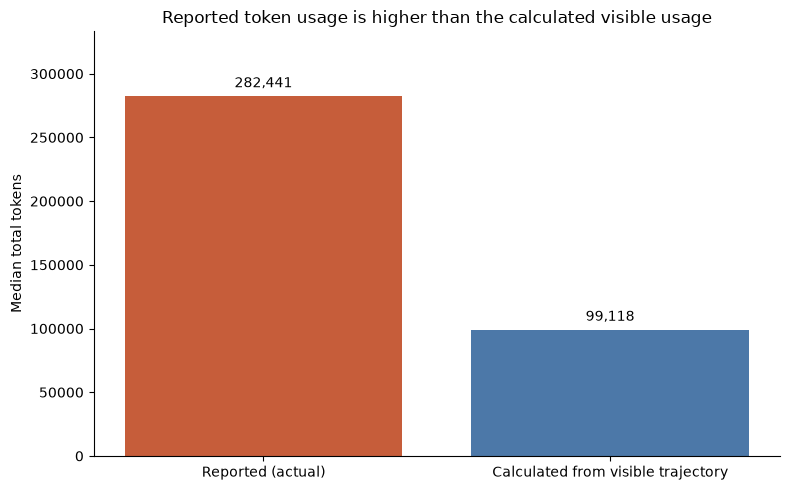

Reported median is 2.85 times the calculated median.


In [44]:
# Simple answer: compare typical reported and calculated token usage using medians.
token_comparison = pd.Series({
    "Reported (actual)": reported["reported_total_tokens"].median(),
    "Calculated from visible trajectory": reported["calculated_cumulative_total_tokens"].median(),
})

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(token_comparison.index, token_comparison.values, color=["#C65D3A", "#4C78A8"])
ax.bar_label(bars, labels=[f"{value:,.0f}" for value in token_comparison.values], padding=4)
ax.set_ylabel("Median total tokens")
ax.set_title("Reported token usage is higher than the calculated visible usage")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, token_comparison.max() * 1.18)
plt.tight_layout()
plt.show()

print(f"Reported median is {token_comparison.iloc[0] / token_comparison.iloc[1]:.2f} times the calculated median.")

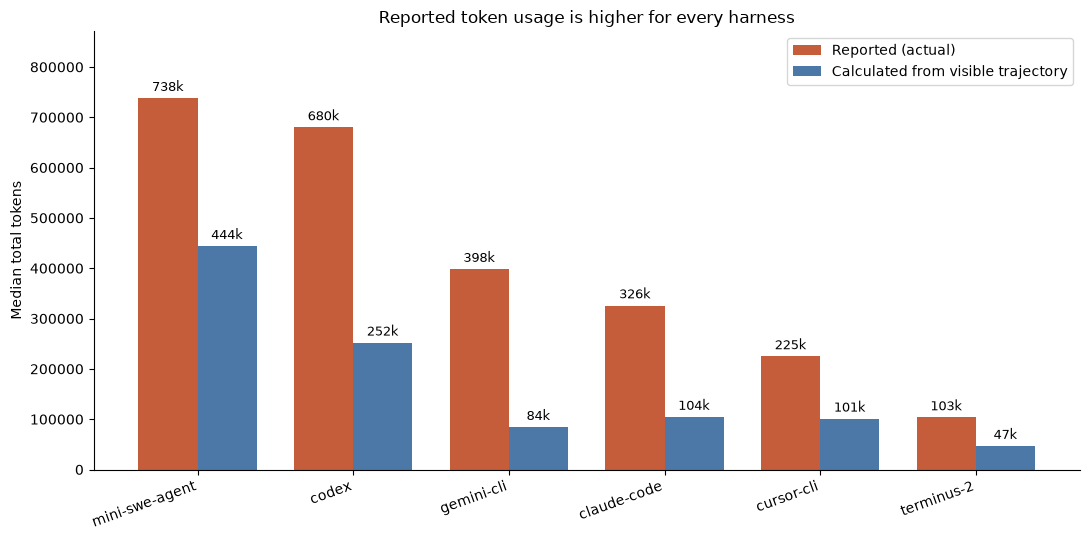

,reported_median,calculated_median
agent,,
mini-swe-agent,737946.0,443803.0
codex,679840.0,251913.0
gemini-cli,398234.0,84227.0
claude-code,325944.0,104392.0
cursor-cli,224800.0,100838.0
terminus-2,103448.0,46610.0


In [45]:
# Harness-wise comparison using the median across trajectories with reported token data.
harness_comparison = (
    reported.groupby("agent")
    .agg(
        reported_median=("reported_total_tokens", "median"),
        calculated_median=("calculated_cumulative_total_tokens", "median"),
    )
    .sort_values("reported_median", ascending=False)
)

x = np.arange(len(harness_comparison))
width = 0.38
fig, ax = plt.subplots(figsize=(11, 5.5))
reported_bars = ax.bar(
    x - width / 2, harness_comparison["reported_median"], width,
    label="Reported (actual)", color="#C65D3A",
)
calculated_bars = ax.bar(
    x + width / 2, harness_comparison["calculated_median"], width,
    label="Calculated from visible trajectory", color="#4C78A8",
)
ax.bar_label(reported_bars, labels=[f"{v / 1000:,.0f}k" for v in harness_comparison["reported_median"]], padding=3, fontsize=9)
ax.bar_label(calculated_bars, labels=[f"{v / 1000:,.0f}k" for v in harness_comparison["calculated_median"]], padding=3, fontsize=9)
ax.set_xticks(x, harness_comparison.index, rotation=20, ha="right")
ax.set_ylabel("Median total tokens")
ax.set_title("Reported token usage is higher for every harness")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, harness_comparison[["reported_median", "calculated_median"]].to_numpy().max() * 1.18)
plt.tight_layout()
plt.show()

harness_comparison.round(0)

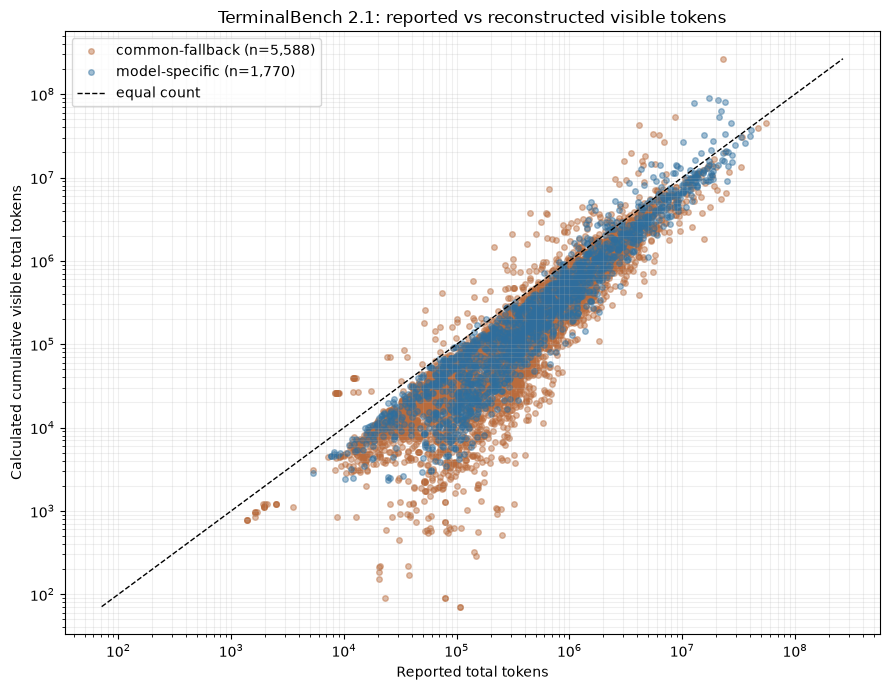

In [46]:
plot_df = reported[(reported["reported_total_tokens"] > 0) & (reported["calculated_cumulative_total_tokens"] > 0)].copy()
colors = {"model-specific": "#2F6F9E", "family-specific": "#4E8C72", "common-fallback": "#B96B3C"}

fig, ax = plt.subplots(figsize=(9, 7))
for quality, group in plot_df.groupby("counter_quality"):
    ax.scatter(
        group["reported_total_tokens"],
        group["calculated_cumulative_total_tokens"],
        s=16, alpha=0.45, label=f"{quality} (n={len(group):,})",
        color=colors.get(quality, "#777777"),
    )
low = max(1, min(plot_df["reported_total_tokens"].min(), plot_df["calculated_cumulative_total_tokens"].min()))
high = max(plot_df["reported_total_tokens"].max(), plot_df["calculated_cumulative_total_tokens"].max())
ax.plot([low, high], [low, high], linestyle="--", color="black", linewidth=1, label="equal count")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Reported total tokens")
ax.set_ylabel("Calculated cumulative visible total tokens")
ax.set_title("TerminalBench 2.1: reported vs reconstructed visible tokens")
ax.grid(alpha=0.2, which="both")
ax.legend()
plt.tight_layout()
plt.show()

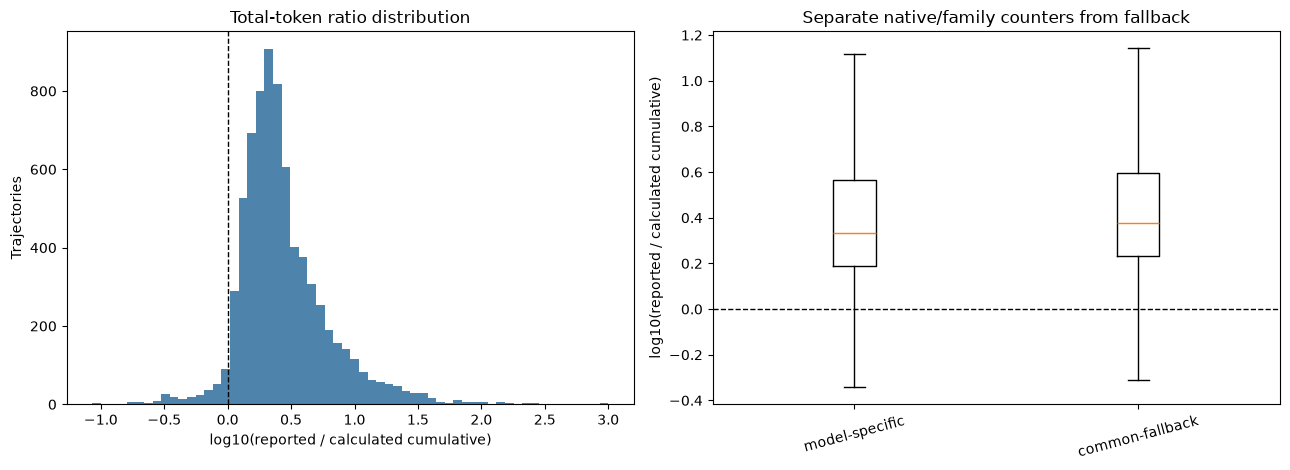

In [47]:
ratio_df = reported[reported["reported_to_calculated_cumulative_ratio"] > 0].copy()
ratio_df["log10_reported_to_calculated"] = np.log10(ratio_df["reported_to_calculated_cumulative_ratio"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].hist(ratio_df["log10_reported_to_calculated"].clip(-3, 3), bins=60, color="#2F6F9E", alpha=0.85)
axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_xlabel("log10(reported / calculated cumulative)")
axes[0].set_ylabel("Trajectories")
axes[0].set_title("Total-token ratio distribution")

quality_order = [q for q in ["model-specific", "family-specific", "common-fallback"] if q in ratio_df["counter_quality"].unique()]
box_data = [ratio_df.loc[ratio_df["counter_quality"] == q, "log10_reported_to_calculated"].clip(-3, 3) for q in quality_order]
axes[1].boxplot(box_data, tick_labels=quality_order, showfliers=False)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_ylabel("log10(reported / calculated cumulative)")
axes[1].set_title("Separate native/family counters from fallback")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

In [48]:
def grouped_summary(frame: pd.DataFrame, group_columns: list[str]) -> pd.DataFrame:
    result = (
        frame.groupby(group_columns, dropna=False)
        .agg(
            trajectories=("id", "size"),
            reported_available=("reported_available", "sum"),
            median_reported_total=("reported_total_tokens", "median"),
            median_calculated_total=("calculated_cumulative_total_tokens", "median"),
            median_reported_to_calculated=("reported_to_calculated_cumulative_ratio", "median"),
            median_abs_pct_error=("cumulative_total_abs_pct_error", "median"),
            median_completion_ratio=("reported_to_calculated_completion_ratio", "median"),
        )
        .reset_index()
    )
    result["reported_coverage_pct"] = 100 * result["reported_available"] / result["trajectories"]
    return result

model_summary = grouped_summary(audit_df, ["model", "counter_quality", "counter_method"])
agent_summary = grouped_summary(audit_df, ["agent", "counter_quality"])

if MAX_TRAJECTORIES is None:
    model_summary.to_csv(MODEL_SUMMARY_CSV, index=False)
    agent_summary.to_csv(AGENT_SUMMARY_CSV, index=False)

display(Markdown("### By model"))
display(model_summary.sort_values("trajectories", ascending=False))
display(Markdown("### By harness"))
display(agent_summary.sort_values("trajectories", ascending=False))

### By model

,model,counter_quality,counter_method,trajectories,reported_available,median_reported_total,median_calculated_total,median_reported_to_calculated,median_abs_pct_error,median_completion_ratio,reported_coverage_pct
16,gpt-5.6-terra,model-specific,tiktoken:o200k_base:registry,856,444,547194.5,203784.0,2.708921,0.638698,3.008134,51.869159
14,gpt-5.6-luna,model-specific,tiktoken:o200k_base:registry,853,441,837742.0,328644.0,2.360593,0.591654,2.950977,51.699883
5,claude-opus-4-8,common-fallback,tiktoken:o200k_base:common-fallback,539,539,160782.0,79352.0,1.946681,0.527046,4.931327,100.000000
18,openai/muse-spark-1.1,common-fallback,tiktoken:o200k_base:common-fallback,445,445,737946.0,443803.0,1.469567,0.319527,3.034352,100.000000
1,anthropic/claude-fable-5,common-fallback,tiktoken:o200k_base:common-fallback,444,444,75697.0,28787.5,2.305108,0.566180,238.896739,100.000000
13,gpt-5.5,model-specific,tiktoken:o200k_base:registry,443,443,680616.0,246658.0,2.362313,0.600998,7.825397,100.000000
10,gemini/gemini-3-pro-preview,common-fallback,tiktoken:o200k_base:common-fallback,443,443,89590.0,40622.0,2.151928,0.535300,414.725806,100.000000
9,gemini-3.1-pro-preview-customtools,common-fallback,tiktoken:o200k_base:common-fallback,443,443,332033.0,62719.0,5.620051,0.822066,13.917172,100.000000
17,openai/gpt-5.5,model-specific,tiktoken:o200k_base:registry,442,442,91713.0,50467.5,1.765100,0.433460,536.317308,100.000000
4,claude-opus-4-7,common-fallback,tiktoken:o200k_base:common-fallback,437,431,724288.0,146980.0,4.259312,0.788368,10.508531,98.627002


### By harness

,agent,counter_quality,trajectories,reported_available,median_reported_total,median_calculated_total,median_reported_to_calculated,median_abs_pct_error,median_completion_ratio,reported_coverage_pct
1,codex,model-specific,2559,1328,679839.5,241797.0,2.504981,0.611506,3.573377,51.895272
0,claude-code,common-fallback,2198,2192,325944.5,104392.5,2.307600,0.602549,5.431442,99.727025
5,terminus-2,common-fallback,1732,1732,106670.0,45985.0,2.232470,0.552066,312.183333,100.000000
3,gemini-cli,common-fallback,859,859,398234.0,84227.0,4.942451,0.797671,9.435313,100.000000
4,mini-swe-agent,common-fallback,445,445,737946.0,443803.0,1.469567,0.319527,3.034352,100.000000
6,terminus-2,model-specific,442,442,91713.0,50467.5,1.765100,0.433460,536.317308,100.000000
2,cursor-cli,common-fallback,405,366,224800.5,100918.0,2.251558,0.557981,2.932631,90.370370


In [49]:
outlier_df = reported[reported["reported_to_calculated_cumulative_ratio"] > 0].copy()
outlier_df["absolute_log10_ratio"] = np.log10(outlier_df["reported_to_calculated_cumulative_ratio"]).abs()
outlier_columns = [
    "id", "task_name", "agent", "model", "resolved", "counter_quality",
    "normalized_step_count", "inferred_model_turn_count",
    "reported_prompt_tokens", "reported_completion_tokens", "reported_total_tokens",
    "calculated_cumulative_prompt_tokens", "calculated_completion_tokens",
    "calculated_cumulative_total_tokens", "reported_to_calculated_cumulative_ratio",
    "steps_with_thought", "steps_with_action", "steps_with_observation", "trajectory_file",
]
outlier_df.nlargest(25, "absolute_log10_ratio")[outlier_columns]

,id,task_name,agent,model,resolved,counter_quality,normalized_step_count,inferred_model_turn_count,reported_prompt_tokens,reported_completion_tokens,reported_total_tokens,calculated_cumulative_prompt_tokens,calculated_completion_tokens,calculated_cumulative_total_tokens,reported_to_calculated_cumulative_ratio,steps_with_thought,steps_with_action,steps_with_observation,trajectory_file
1142,tbench21:9e10c1e4-5a81-5a09-aba6-e5edcafc3b83,chess-best-move,claude-code,claude-opus-4-7,False,common-fallback,1,1,43868.0,64125.0,107993.0,70,1,71,1521.028169,0,1,1,claude-code\claude-opus-4-7\chess-best-move_9e10c1e4-5a81-5a09-aba6-e5edcafc3b83.json
1278,tbench21:e5560b7f-69d8-505c-b0a3-24df42ff2432,chess-best-move,claude-code,claude-opus-4-7,False,common-fallback,1,1,43864.0,64121.0,107985.0,70,1,71,1520.915493,0,1,1,claude-code\claude-opus-4-7\chess-best-move_e5560b7f-69d8-505c-b0a3-24df42ff2432.json
727,tbench21:a8a3f3db-dae7-5e8e-9647-384b4348ab3d,write-compressor,claude-code,glm-5.1,False,common-fallback,2,1,47363.0,32057.0,79420.0,87,2,89,892.359551,0,2,2,claude-code\glm-5.1\write-compressor_a8a3f3db-dae7-5e8e-9647-384b4348ab3d.json
772,tbench21:c03e4bf2-004f-50e6-acb0-b296615493dd,write-compressor,claude-code,glm-5.1,False,common-fallback,2,1,47346.0,32040.0,79386.0,87,2,89,891.977528,0,2,2,claude-code\glm-5.1\write-compressor_c03e4bf2-004f-50e6-acb0-b296615493dd.json
795,tbench21:cc949505-3fdf-5310-bf0f-df3eb05a9056,schemelike-metacircular-eval,claude-code,glm-5.1,False,common-fallback,1,1,84651.0,64146.0,148797.0,285,5,290,513.093103,1,1,1,claude-code\glm-5.1\schemelike-metacircular-eval_cc949505-3fdf-5310-bf0f-df3eb05a9056.json
569,tbench21:50aea00a-b2ba-5564-a789-47b46d015a2d,regex-chess,claude-code,glm-5.1,False,common-fallback,1,1,121465.0,128187.0,249652.0,517,1,518,481.953668,0,1,1,claude-code\glm-5.1\regex-chess_50aea00a-b2ba-5564-a789-47b46d015a2d.json
639,tbench21:74c673c7-176a-51e4-ae35-6f6d41ae013e,feal-linear-cryptanalysis,claude-code,glm-5.1,False,common-fallback,5,2,79427.0,64176.0,143603.0,304,18,322,445.972050,1,4,4,claude-code\glm-5.1\feal-linear-cryptanalysis_74c673c7-176a-51e4-ae35-6f6d41ae013e.json
1560,tbench21:8b34d753-f8ac-5315-84d9-1a037cc99865,regex-chess,claude-code,claude-opus-4-8,False,common-fallback,2,1,22193.0,133722.0,155915.0,517,41,558,279.417563,0,2,1,claude-code\claude-opus-4-8\regex-chess_8b34d753-f8ac-5315-84d9-1a037cc99865.json
878,tbench21:0438b7b7-52ae-527b-8367-ce2afffdf5bb,regex-chess,claude-code,claude-opus-4-7,False,common-fallback,2,2,128656.0,192259.0,320915.0,1198,14,1212,264.781353,1,2,2,claude-code\claude-opus-4-7\regex-chess_0438b7b7-52ae-527b-8367-ce2afffdf5bb.json
702,tbench21:99787743-9850-5c53-8e69-4bfc8d6ed834,write-compressor,claude-code,glm-5.1,False,common-fallback,2,1,22915.0,40.0,22955.0,87,2,89,257.921348,0,2,2,claude-code\glm-5.1\write-compressor_99787743-9850-5c53-8e69-4bfc8d6ed834.json


In [50]:
median_once_ape = reported["once_total_abs_pct_error"].median()
median_cumulative_ape = reported["cumulative_total_abs_pct_error"].median()
median_total_ratio = reported["reported_to_calculated_cumulative_ratio"].replace([np.inf, -np.inf], np.nan).median()
median_prompt_ratio = reported["reported_to_calculated_prompt_ratio"].replace([np.inf, -np.inf], np.nan).median()
median_completion_ratio = reported["reported_to_calculated_completion_ratio"].replace([np.inf, -np.inf], np.nan).median()
reported_coverage = 100 * len(reported) / len(audit_df)

if median_cumulative_ape < median_once_ape:
    context_result = "Counting repeated visible history is closer to the reported totals than counting the transcript once. This supports cumulative context as an important part of reported prompt usage."
else:
    context_result = "The cumulative reconstruction is not closer than the one-pass lower bound. Inferred model-turn boundaries or context-retention assumptions require inspection before interpreting the gap."

display(Markdown(f"""
## Findings generated from the executed audit

- **Corpus:** {len(audit_df):,} TerminalBench 2.1 trajectories were traversed.
- **Reported-token coverage:** {len(reported):,}/{len(audit_df):,} ({reported_coverage:.1f}%). Missing reported values remain explicit rather than being filled from calculated counts.
- **Median reported/calculated cumulative total ratio:** {median_total_ratio:.2f}×.
- **Median reported/calculated cumulative prompt ratio:** {median_prompt_ratio:.2f}×.
- **Median reported/calculated visible completion ratio:** {median_completion_ratio:.2f}×.
- **Median absolute percentage error:** one-pass lower bound {median_once_ape:.1%}; cumulative visible reconstruction {median_cumulative_ape:.1%}.
- **Context interpretation:** {context_result}

### Thesis interpretation

The calculated value measures content observable in the stored trajectory. A systematic remaining difference is evidence of a **token-accounting and observability gap**, but it cannot by itself identify hidden reasoning. The gap must be analysed alongside tokenizer quality, harness, model, inferred call count, thought coverage, observation coverage and possible missing system/tool context. Results produced with `common-fallback` counters should be described as sensitivity estimates, not native-model token counts.
"""))


## Findings generated from the executed audit

- **Corpus:** 8,640 TerminalBench 2.1 trajectories were traversed.
- **Reported-token coverage:** 7,364/8,640 (85.2%). Missing reported values remain explicit rather than being filled from calculated counts.
- **Median reported/calculated cumulative total ratio:** 2.33×.
- **Median reported/calculated cumulative prompt ratio:** 2.03×.
- **Median reported/calculated visible completion ratio:** 7.89×.
- **Median absolute percentage error:** one-pass lower bound 95.9%; cumulative visible reconstruction 58.2%.
- **Context interpretation:** Counting repeated visible history is closer to the reported totals than counting the transcript once. This supports cumulative context as an important part of reported prompt usage.

### Thesis interpretation

The calculated value measures content observable in the stored trajectory. A systematic remaining difference is evidence of a **token-accounting and observability gap**, but it cannot by itself identify hidden reasoning. The gap must be analysed alongside tokenizer quality, harness, model, inferred call count, thought coverage, observation coverage and possible missing system/tool context. Results produced with `common-fallback` counters should be described as sensitivity estimates, not native-model token counts.


## Saved outputs

After a complete run, the notebook writes three files under `design-decisions-by-LLMs/outputs/`:

- `terminalbench21_token_audit.csv` — one row per TerminalBench 2.1 trajectory;
- `terminalbench21_token_audit_by_model.csv` — model/counter summary; and
- `terminalbench21_token_audit_by_agent.csv` — harness/counter summary.

Keep `counter_method`, `counter_quality`, `reported_available` and `audit_version` whenever exporting or plotting these results.